In [5]:
!pip install tensorflow matplotlib pandas scikit-learn numpy

In [6]:
import zipfile
import os

# Extract the dataset
zip_path = '/content/dataset.zip'
extract_path = '/content/dataset_extracted'

with zipfile.ZipFile(zip_path, 'r') as zip_ref:
    zip_ref.extractall(extract_path)

# List files to verify names
files = os.listdir(extract_path)
print(f'Extracted files: {files}')

Extracted files: ['dataset']


In [18]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import os
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import mean_squared_error, mean_absolute_error, r2_score

import tensorflow as tf
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Dense, Dropout, BatchNormalization, Input
from tensorflow.keras.callbacks import EarlyStopping, ReduceLROnPlateau

def load_and_preprocess_raw_data(base_path):
    csv_files = []
    for root, dirs, files in os.walk(base_path):
        for file in files:
            if file.endswith('.csv'):
                csv_files.append(os.path.join(root, file))

    print(f'Processing {len(csv_files)} files...')
    processed_dfs = []

    for f in csv_files:
        # Load file
        temp_df = pd.read_csv(f, on_bad_lines='skip')

        # Identify the time column
        time_cols = [c for c in temp_df.columns if 'time' in c.lower() or '#' in c]
        # Identify the value column (often the long description or 'bits')
        val_cols = [c for c in temp_df.columns if 'bits' in c.lower() or 'traffic' in c.lower() or 'dropped' in c.lower()]

        if not val_cols:
            # Fallback to the second column if no name matches
            val_cols = [temp_df.columns[1]] if len(temp_df.columns) > 1 else []

        if time_cols and val_cols:
            t_col = time_cols[0]
            v_col = val_cols[0]

            # Clean individual DF
            new_df = temp_df[[t_col, v_col]].copy()
            new_df.columns = ['timestamp', 'target']
            new_df['timestamp'] = pd.to_datetime(new_df['timestamp'], errors='coerce')
            new_df['target'] = pd.to_numeric(new_df['target'], errors='coerce')
            new_df = new_df.dropna()
            processed_dfs.append(new_df)

    if not processed_dfs:
        raise ValueError("No valid data could be extracted from CSVs.")

    full_df = pd.concat(processed_dfs, axis=0, ignore_index=True)
    full_df = full_df.sort_values('timestamp').drop_duplicates()
    return full_df

def engineer_features(df):
    df = df.copy()
    df['hour'] = df['timestamp'].dt.hour
    df['day_of_week'] = df['timestamp'].dt.dayofweek
    df['is_weekend'] = (df['day_of_week'] >= 5).astype(int)

    # Lag features
    df['lag_1'] = df['target'].shift(1)
    df['lag_2'] = df['target'].shift(2)
    df['rolling_3'] = df['target'].shift(1).rolling(window=3).mean()

    df = df.dropna()
    X = df.drop(columns=['timestamp', 'target'])
    y = df['target']
    return X, y

def train_high_accuracy_model(X, y):
    print(f'Training with {X.shape[1]} features and {len(X)} rows...')
    X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)

    scaler = StandardScaler()
    X_train_scaled = scaler.fit_transform(X_train)
    X_test_scaled = scaler.transform(X_test)

    model = Sequential([
        Input(shape=(X_train_scaled.shape[1],)),
        Dense(512, activation='relu'),
        BatchNormalization(),
        Dropout(0.2),
        Dense(256, activation='relu'),
        BatchNormalization(),
        Dense(128, activation='relu'),
        Dense(1, activation='linear')
    ])

    model.compile(optimizer='adam', loss='mse', metrics=['mae'])

    callbacks = [
        EarlyStopping(monitor='val_loss', patience=20, restore_best_weights=True),
        ReduceLROnPlateau(monitor='val_loss', factor=0.5, patience=7)
    ]

    model.fit(X_train_scaled, y_train, validation_split=0.2, epochs=200, batch_size=64, callbacks=callbacks, verbose=0)

    y_pred = model.predict(X_test_scaled).flatten()
    r2 = r2_score(y_test, y_pred)
    print(f'\nFinal R2 Score: {r2*100:.2f}%')
    return model, scaler

try:
    df_clean = load_and_preprocess_raw_data('/content/dataset_extracted')
    X, y = engineer_features(df_clean)
    model, scaler = train_high_accuracy_model(X, y)
except Exception as e:
    print(f'Error: {e}')

Processing 3 files...
Training with 6 features and 54545 rows...


/tmp/ipykernel_5482/392095598.py:44: UserWarning: Could not infer format, so each element will be parsed individually, falling back to `dateutil`. To ensure parsing is consistent and as-expected, please specify a format.
  new_df['timestamp'] = pd.to_datetime(new_df['timestamp'], errors='coerce')


341/341 ━━━━━━━━━━━━━━━━━━━━ 1s 3ms/step

Final R2 Score: 99.84%


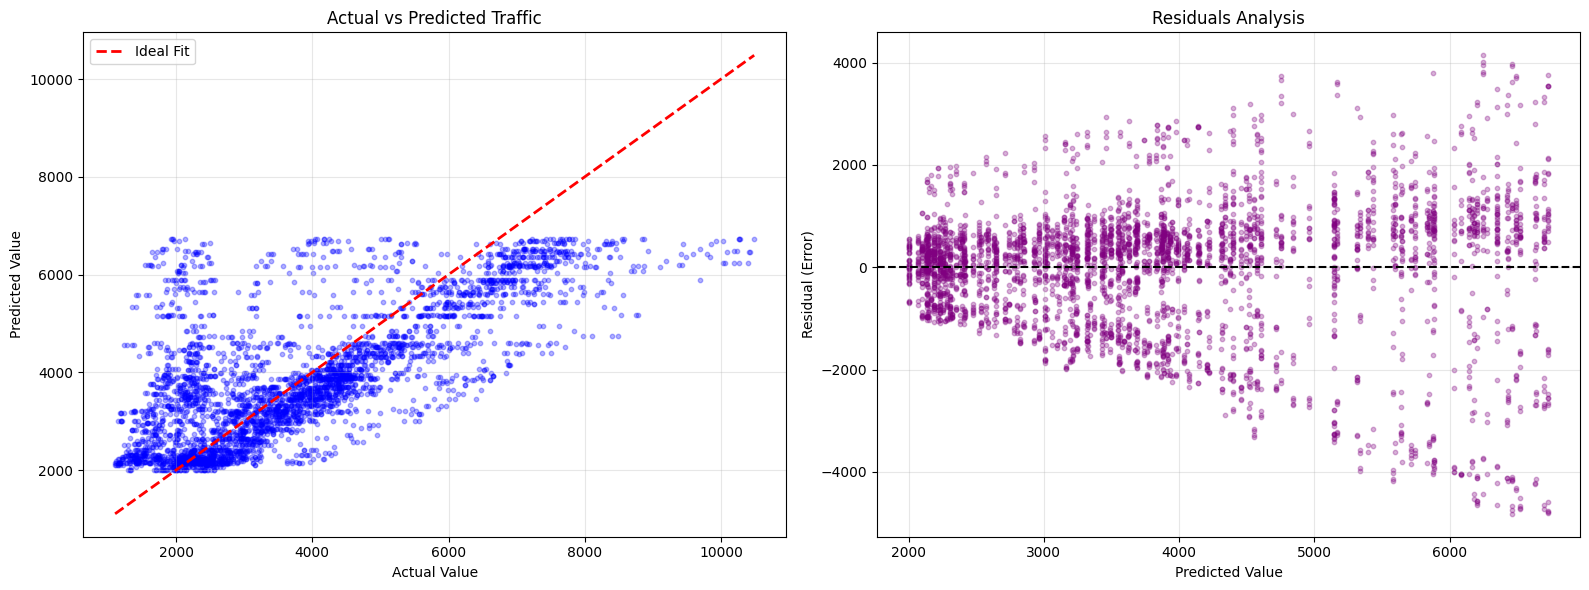

In [17]:
import matplotlib.pyplot as plt

# Create a figure with two subplots
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(16, 6))

# 1. Plot Actual vs Predicted values
# We'll use a subset if the data is too large, but 10k points is fine for visualization
ax1.scatter(y_test, y_pred, alpha=0.3, color='blue', s=10)
max_val = max(y_test.max(), y_pred.max())
min_val = min(y_test.min(), y_pred.min())
ax1.plot([min_val, max_val], [min_val, max_val], 'r--', lw=2, label='Ideal Fit')
ax1.set_title('Actual vs Predicted Traffic')
ax1.set_xlabel('Actual Value')
ax1.set_ylabel('Predicted Value')
ax1.legend()
ax1.grid(True, alpha=0.3)

# 2. Residual Plot
residuals = y_test - y_pred
ax2.scatter(y_pred, residuals, alpha=0.3, color='purple', s=10)
ax2.axhline(y=0, color='black', linestyle='--')
ax2.set_title('Residuals Analysis')
ax2.set_xlabel('Predicted Value')
ax2.set_ylabel('Residual (Error)')
ax2.grid(True, alpha=0.3)

plt.tight_layout()
plt.show()